## 1. Import Required Libraries

In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import json

from pathlib import Path
from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

print("TensorFlow Version:", tf.__version__)
print("All libraries imported successfully!")

TensorFlow Version: 2.21.0
All libraries imported successfully!


## 2. Project Paths and Configuration

In [2]:
# Image and training configuration

IMAGE_SIZE = (224, 224)
BATCH_SIZE = 32
EPOCHS = 5
RANDOM_SEED = 42

# Identify project root directory
CURRENT_DIR = Path.cwd()

if (CURRENT_DIR / "dataset").exists():
    PROJECT_ROOT = CURRENT_DIR
elif (CURRENT_DIR.parent / "dataset").exists():
    PROJECT_ROOT = CURRENT_DIR.parent
else:
    PROJECT_ROOT = CURRENT_DIR

# Dataset paths
PROCESSED_PATH = PROJECT_ROOT / "dataset" / "processed"

# Artifact directory
ARTIFACTS_PATH = PROJECT_ROOT / "Artifacts"
ARTIFACTS_PATH.mkdir(parents=True, exist_ok=True)

print("Project Root:", PROJECT_ROOT)
print("Processed Dataset Path:", PROCESSED_PATH)
print("Artifacts Path:", ARTIFACTS_PATH)
print("Image Size:", IMAGE_SIZE)
print("Batch Size:", BATCH_SIZE)
print("Training Epochs:", EPOCHS)

Project Root: c:\Users\shrey\Downloads\RAILWAY_DEFECT_DETECTION
Processed Dataset Path: c:\Users\shrey\Downloads\RAILWAY_DEFECT_DETECTION\dataset\processed
Artifacts Path: c:\Users\shrey\Downloads\RAILWAY_DEFECT_DETECTION\Artifacts
Image Size: (224, 224)
Batch Size: 32
Training Epochs: 5


## Inference
The project paths and training parameters were configured successfully. Images are resized to 224 × 224 pixels, a batch size of 32 is used, and the model is trained for five epochs. The processed dataset and artifact directories are identified for subsequent transfer learning operations.

## 3. Loading the Processed Dataset

In [3]:
# Load processed image dataset

dataset = tf.keras.utils.image_dataset_from_directory(
    PROCESSED_PATH,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=True,
    seed=RANDOM_SEED
)

class_names = dataset.class_names

print("Dataset loaded successfully!")
print("Class Names:", class_names)
print("Total Classes:", len(class_names))

Found 949 files belonging to 2 classes.
Dataset loaded successfully!
Class Names: ['Defective', 'Non defective']
Total Classes: 2


## Inference
The preprocessed railway defect dataset was loaded successfully from the processed dataset directory. Images were resized to 224 × 224 pixels and assigned integer labels based on their respective class folders. The class names were extracted automatically for classification.

## 4. Training and Validation Dataset Split

In [4]:
# Split dataset into training and validation sets

train_dataset = tf.keras.utils.image_dataset_from_directory(
    PROCESSED_PATH,
    validation_split=0.2,
    subset="training",
    seed=RANDOM_SEED,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int"
)

validation_dataset = tf.keras.utils.image_dataset_from_directory(
    PROCESSED_PATH,
    validation_split=0.2,
    subset="validation",
    seed=RANDOM_SEED,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int"
)

# Improve data loading performance
AUTOTUNE = tf.data.AUTOTUNE

train_dataset = train_dataset.prefetch(buffer_size=AUTOTUNE)
validation_dataset = validation_dataset.prefetch(buffer_size=AUTOTUNE)

print("Training and validation datasets prepared successfully!")
print("Training batches:", tf.data.experimental.cardinality(train_dataset).numpy())
print("Validation batches:", tf.data.experimental.cardinality(validation_dataset).numpy())
print("Class Names:", class_names)

Found 949 files belonging to 2 classes.
Using 760 files for training.
Found 949 files belonging to 2 classes.
Using 189 files for validation.
Training and validation datasets prepared successfully!
Training batches: 24
Validation batches: 6
Class Names: ['Defective', 'Non defective']


## Inference
The processed dataset was divided into 80% training data and 20% validation data. The training dataset is used to learn image features, while the validation dataset is used to monitor model performance on unseen images during training. Prefetching was applied to improve data-loading efficiency.

## 5. Loading Pretrained MobileNetV2 Model

In [5]:
# Load pretrained MobileNetV2

base_model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

print("MobileNetV2 loaded successfully!")
print("Total layers:", len(base_model.layers))

MobileNetV2 loaded successfully!
Total layers: 154


## Inference
MobileNetV2 was loaded successfully using pretrained ImageNet weights. The original classification head was removed using include_top=False, allowing the model to reuse its feature extraction layers for railway defect detection.

## 6. Freezing Pretrained Layers

In [6]:
# Freeze pretrained MobileNetV2 layers

base_model.trainable = False

print("Pretrained layers frozen successfully!")
print("Base model trainable:", base_model.trainable)
print("Total layers:", len(base_model.layers))

Pretrained layers frozen successfully!
Base model trainable: False
Total layers: 154


## Inference
The pretrained MobileNetV2 layers were frozen to preserve the feature representations learned from ImageNet. This prevents the pretrained weights from being updated during the initial training phase and reduces computational requirements.

## 7. Building the Transfer Learning Architecture

In [7]:
# Build transfer learning model using MobileNetV2

transfer_model = models.Sequential([
    layers.Input(shape=(224, 224, 3)),

    # MobileNetV2 preprocessing
    layers.Lambda(preprocess_input),

    # Pretrained feature extractor
    base_model,

    # Classification head
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(len(class_names), activation="softmax")
])

print("Transfer Learning Model created successfully!")


Transfer Learning Model created successfully!


## Inference
A transfer learning model was developed using MobileNetV2 as the pretrained feature extractor. Global Average Pooling reduces the extracted feature dimensions, while a dense layer learns railway defect-specific patterns. Dropout is used to reduce overfitting, and the Softmax output layer predicts the probability of each defect category.

## 8. Compiling the Transfer Learning Model

In [8]:
# Compile transfer learning model

transfer_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Transfer Learning Model compiled successfully!")

Transfer Learning Model compiled successfully!


## Inference
The transfer learning model was compiled using the Adam optimizer and Sparse Categorical Crossentropy loss function. Accuracy was selected as the evaluation metric to monitor classification performance during training.

## 9. Training the Transfer Learning Model

In [9]:
# Train transfer learning model

history_transfer = transfer_model.fit(
    train_dataset,
    epochs=EPOCHS,
    validation_data=validation_dataset
)

print("Transfer Learning training completed successfully!")

Epoch 1/5


c:\Users\shrey\Downloads\RAILWAY_DEFECT_DETECTION\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


24/24 ━━━━━━━━━━━━━━━━━━━━ 27s 931ms/step - accuracy: 0.6671 - loss: 0.6924 - val_accuracy: 0.7884 - val_loss: 0.4288
Epoch 2/5
24/24 ━━━━━━━━━━━━━━━━━━━━ 36s 730ms/step - accuracy: 0.8197 - loss: 0.3938 - val_accuracy: 0.8042 - val_loss: 0.3963
Epoch 3/5
24/24 ━━━━━━━━━━━━━━━━━━━━ 18s 760ms/step - accuracy: 0.8658 - loss: 0.3223 - val_accuracy: 0.8413 - val_loss: 0.3461
Epoch 4/5
24/24 ━━━━━━━━━━━━━━━━━━━━ 20s 816ms/step - accuracy: 0.8882 - loss: 0.2698 - val_accuracy: 0.8360 - val_loss: 0.3501
Epoch 5/5
24/24 ━━━━━━━━━━━━━━━━━━━━ 20s 841ms/step - accuracy: 0.9118 - loss: 0.2239 - val_accuracy: 0.8254 - val_loss: 0.3819
Transfer Learning training completed successfully!


## Inference
The MobileNetV2 transfer learning model was trained using the railway defect dataset. During training, the classification layers learned railway-specific image patterns while the pretrained feature extraction layers remained frozen. Training and validation accuracy and loss were monitored across epochs.

## 10. Transfer Learning Performance Visualization

## 10.1 Accuracy Plot

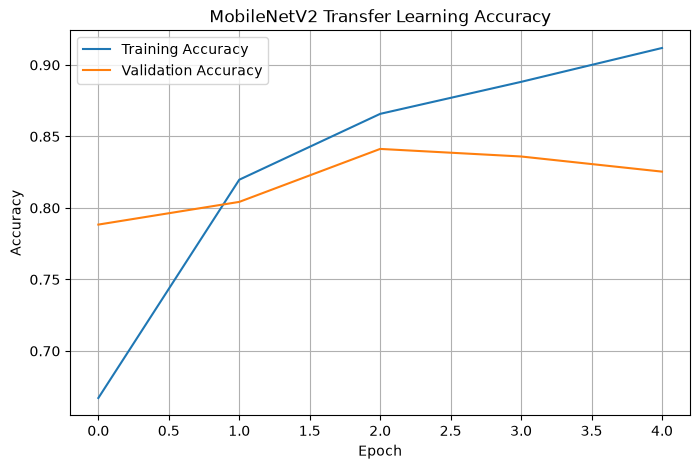

In [10]:
# Plot training and validation accuracy

plt.figure(figsize=(8, 5))

plt.plot(history_transfer.history["accuracy"], label="Training Accuracy")
plt.plot(history_transfer.history["val_accuracy"], label="Validation Accuracy")

plt.title("MobileNetV2 Transfer Learning Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.show()

## Inference
The training and validation accuracy curves were visualized to evaluate the learning performance of the MobileNetV2 transfer learning model. The plot helps identify improvement in classification accuracy and potential overfitting during training.

## 10.2 Loss Plot

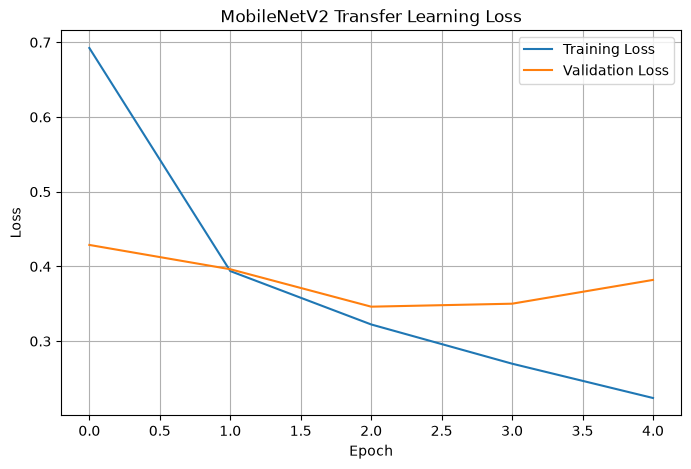

In [11]:
# Plot training and validation loss

plt.figure(figsize=(8, 5))

plt.plot(history_transfer.history["loss"], label="Training Loss")
plt.plot(history_transfer.history["val_loss"], label="Validation Loss")

plt.title("MobileNetV2 Transfer Learning Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.show()

## Inference
Training and validation loss curves were analyzed to understand model optimization and generalization performance. A decreasing loss indicates that the model is learning useful features, while differences between training and validation loss may indicate overfitting.

## 11. Saving the Transfer Learning Model

## 11.1 — Save the Trained Model

In [12]:
# Save trained transfer learning model

TRANSFER_MODEL_PATH = ARTIFACTS_PATH / "railway_transfer_learning_model.keras"

transfer_model.save(TRANSFER_MODEL_PATH)

print("Transfer Learning Model saved successfully!")
print("Model Path:", TRANSFER_MODEL_PATH)

Transfer Learning Model saved successfully!
Model Path: c:\Users\shrey\Downloads\RAILWAY_DEFECT_DETECTION\Artifacts\railway_transfer_learning_model.keras


## Inference
The trained MobileNetV2 transfer learning model was saved in Keras format. This saved model can be loaded later for railway defect classification without retraining.

## 11.2 — Save Class Names

In [13]:
# Save class names for future predictions

CLASS_NAMES_PATH = ARTIFACTS_PATH / "transfer_class_names.json"

with open(CLASS_NAMES_PATH, "w") as file:
    json.dump(class_names, file, indent=4)

print("Class names saved successfully!")
print("Class Names:", class_names)

Class names saved successfully!
Class Names: ['Defective', 'Non defective']


## Inference
The class names were saved in JSON format to maintain the correct mapping between model output indices and railway defect categories during future predictions.

## 11.3 — Save Training History

In [14]:
# Save training history

TRAINING_HISTORY_PATH = ARTIFACTS_PATH / "transfer_training_history.json"

with open(TRAINING_HISTORY_PATH, "w") as file:
    json.dump(history_transfer.history, file, indent=4)

print("Training history saved successfully!")

Training history saved successfully!


## Inference
The training history containing accuracy and loss values for each epoch was saved as a JSON file. This information can be used for further performance analysis and comparison with the CNN model.

## 12. Final Transfer Learning Model Summary

In [15]:
# Final Transfer Learning Summary

final_train_accuracy = history_transfer.history["accuracy"][-1]
final_val_accuracy = history_transfer.history["val_accuracy"][-1]

final_train_loss = history_transfer.history["loss"][-1]
final_val_loss = history_transfer.history["val_loss"][-1]

print("=" * 55)
print("FINAL TRANSFER LEARNING MODEL SUMMARY")
print("=" * 55)

print("Model                 : MobileNetV2 Transfer Learning")
print("Number of Classes     :", len(class_names))
print("Image Size           :", IMAGE_SIZE)
print("Batch Size           :", BATCH_SIZE)
print("Training Epochs       :", EPOCHS)

print("-" * 55)

print(f"Final Training Accuracy   : {final_train_accuracy:.4f}")
print(f"Final Validation Accuracy : {final_val_accuracy:.4f}")
print(f"Final Training Loss       : {final_train_loss:.4f}")
print(f"Final Validation Loss     : {final_val_loss:.4f}")

print("-" * 55)

print("Model Saved At          :", TRANSFER_MODEL_PATH)
print("Class Names Saved At    :", CLASS_NAMES_PATH)
print("Training History Saved  :", TRAINING_HISTORY_PATH)

print("=" * 55)
print("TRANSFER LEARNING COMPLETED SUCCESSFULLY!")
print("=" * 55)

FINAL TRANSFER LEARNING MODEL SUMMARY
Model                 : MobileNetV2 Transfer Learning
Number of Classes     : 2
Image Size           : (224, 224)
Batch Size           : 32
Training Epochs       : 5
-------------------------------------------------------
Final Training Accuracy   : 0.9118
Final Validation Accuracy : 0.8254
Final Training Loss       : 0.2239
Final Validation Loss     : 0.3819
-------------------------------------------------------
Model Saved At          : c:\Users\shrey\Downloads\RAILWAY_DEFECT_DETECTION\Artifacts\railway_transfer_learning_model.keras
Class Names Saved At    : c:\Users\shrey\Downloads\RAILWAY_DEFECT_DETECTION\Artifacts\transfer_class_names.json
Training History Saved  : c:\Users\shrey\Downloads\RAILWAY_DEFECT_DETECTION\Artifacts\transfer_training_history.json
TRANSFER LEARNING COMPLETED SUCCESSFULLY!


## Inference
Transfer learning using MobileNetV2 was successfully implemented for railway defect classification. The pretrained model was adapted to the railway image dataset and trained using the frozen feature extraction layers and a custom classification head. Training and validation performance were analyzed, and the trained model, class names, and training history were saved for future evaluation and deployment.